# Showcase 4: Teach a computer to see
## From simple ML to neural networks: reading handwritten digits

**Part 4 - Data Science and AI.** Uses everything from Lectures 1-10, especially:
- **L09**: NumPy arrays, and "an image is just numbers" (remember the cat?)
- **L10**: Matplotlib plots and the scikit-learn recipe: **create, fit, predict**

**What you'll build:** a program that looks at tiny pictures of handwritten digits and says which digit it is.
You will train **three different models**, hold a fair exam, look at their mistakes,
peek inside a **neural network**, and then try to fool it.

> **Pip says:** "In Lecture 10 the computer learned apples vs bananas from 8 examples.
> Today it studies more than a thousand handwritten digits. Same 3 steps!"

**How to run:** in Colab, *Runtime > Run all*, or press **Shift+Enter** on each cell from top to bottom.
A few tools here are new (we say so when we use them). Don't worry: just run them and read the comments.

## 0. Tools for today
We import some libraries (L09: an app store for code). Everything is pre-installed in Colab, nothing to download.

In [1]:
import numpy as np                       # arrays (L09)
import pandas as pd                      # tables (L09)
import matplotlib.pyplot as plt          # plots (L10)
from sklearn.datasets import load_digits                       # the digit pictures (ship with scikit-learn)
from sklearn.model_selection import train_test_split           # new: practice exam / real exam
from sklearn.neighbors import KNeighborsClassifier             # model 1 (you met it in L10)
from sklearn.tree import DecisionTreeClassifier, export_text   # new: model 2, a decision tree
from sklearn.neural_network import MLPClassifier               # new: model 3, a small neural network
from sklearn.metrics import ConfusionMatrixDisplay             # new: "who got confused with whom" picture
print("All tools loaded!")

All tools loaded!


## 1. Meet the data: handwritten digits
scikit-learn comes with a small collection of handwritten digits, scanned from forms that real people filled in.
Each picture is tiny: **8 x 8 pixels**. Every picture also has the right answer (its **label**): 0 to 9.

In [2]:
digits = load_digits()
print(digits.images.shape)    # (pictures, rows, columns)
print(digits.target[:20])     # the right answers (labels) of the first 20

(1797, 8, 8)
[0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]


Let's look at the first 16 pictures.
`plt.subplot(2, 8, i + 1)` picks spot number `i + 1` in a grid of 2 rows x 8 columns, so we can draw many small pictures in one figure.

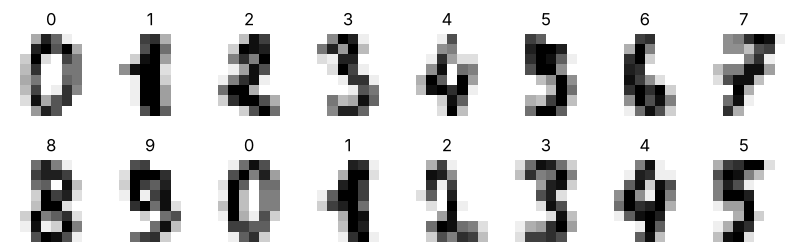

In [3]:
plt.figure(figsize=(10, 3))
for i in range(16):
    plt.subplot(2, 8, i + 1)                        # spot i+1 in a 2 x 8 grid
    plt.imshow(digits.images[i], cmap="gray_r")     # gray_r: 0 = white paper, high = black ink
    plt.title(digits.target[i])                     # the right answer on top
    plt.axis("off")                                 # no ticks around tiny pictures
plt.show()

### An image is just numbers (remember the cat in L09?)
Here is picture number 0 as a table of numbers. **0 = empty paper, 16 = full black ink.**
Can you see the 0 in the numbers?

In [4]:
first_image = digits.images[0]
print(first_image.astype(int))   # astype(int): show 5 instead of 5.0

[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


Same numbers, drawn as a picture, with each number written on its own pixel:

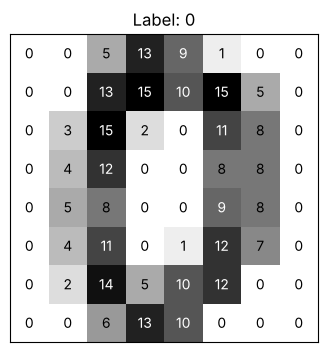

In [5]:
plt.figure(figsize=(4, 4))
plt.imshow(first_image, cmap="gray_r")
for row in range(8):
    for col in range(8):
        value = int(first_image[row, col])
        if value > 8:
            text_color = "white"      # light text on dark pixels
        else:
            text_color = "black"      # dark text on light pixels
        plt.text(col, row, value, ha="center", va="center", color=text_color)
plt.title("Label: " + str(digits.target[0]))
plt.xticks([])                        # no tick numbers, but keep the frame
plt.yticks([])
plt.show()

**Try this**
- Change `digits.images[0]` to `digits.images[7]`. Which digit is it? Can you see it in the numbers?
- Print `first_image.max()` and `first_image.mean()`. What do they tell you about the picture?

## 2. Practice exam vs real exam
If we test a model on the same pictures it studied, it could just **memorize** them. Like a student who saw the exam in advance.
So we split the pictures:
- **75% practice exam** (`train`): the model studies these, with the answers.
- **25% real exam** (`test`): hidden during studying. We use them only to grade the model.

`digits.data` holds the same pictures, but each one is **flattened** into one row of 64 numbers
(row 0 of the picture, then row 1, ...). Models want one row per example, like a table.
We divide by 16 so every pixel is between 0 (paper) and 1 (ink): vectorized math from L09.
So `X` is a table with 1797 rows (pictures) and 64 columns (pixels). `test_size=0.25` hides 25% for the real exam,
and `random_state=7` makes the split the same every time you run it.

In [6]:
X = digits.data / 16      # 64 numbers per picture, from 0 to 1
y = digits.target         # the right answers: 0 to 9
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=7)   # 75% / 25%, same split every run
print("Practice exam:", len(X_train), "pictures")
print("Real exam:    ", len(X_test), "pictures")

Practice exam: 1347 pictures
Real exam:     450 pictures


## 3. A ladder of models, same 3 steps
Every model follows the recipe from L10:
1. **create** the model
2. **fit** = study the practice exam (pictures + answers)
3. **predict** = write the real exam (pictures only)

Then we grade the exam. Grading is the same for every model, so we write it **once** as a function (L07):

In [7]:
def grade_exam(model_name, predictions):
    correct = (predictions == y_test).sum()      # compare all answers at once; True counts as 1
    accuracy = 100 * correct / len(y_test)       # percent correct
    print(f"{model_name}: {correct} of {len(y_test)} correct ({accuracy:.1f}%)")
    return accuracy

### Rung 1: k-nearest neighbours (you met it in L10)
For each new picture: find the **3 practice pictures that look most similar** (pixel by pixel), and take a majority vote.
Like asking "which digits does this remind me of?"

In [8]:
knn = KNeighborsClassifier(n_neighbors=3)    # 1. create
knn.fit(X_train, y_train)                    # 2. fit = study
knn_predictions = knn.predict(X_test)        # 3. predict = real exam
knn_accuracy = grade_exam("k-nearest neighbours", knn_predictions)

k-nearest neighbours: 442 of 450 correct (98.2%)


### Rung 2: a decision tree = a game of "20 questions"
A decision tree asks **yes/no questions** about pixels, one after the other: *"Is this pixel almost empty?"*
First, a **tiny** tree that may ask only 2 questions, so we can read them.
We give every pixel a readable name: pixel number `i` sits in row `i // 8` and column `i % 8` (L02 maths!).

In [9]:
pixel_names = []
for i in range(64):
    pixel_names.append(f"pixel(row {i // 8}, col {i % 8})")
print(pixel_names[:3])

['pixel(row 0, col 0)', 'pixel(row 0, col 1)', 'pixel(row 0, col 2)']


The tiny tree: `max_depth=2` = at most 2 questions in a row. `export_text` prints the questions it chose.

In [10]:
tiny_tree = DecisionTreeClassifier(max_depth=2, random_state=7)
tiny_tree.fit(X_train, y_train)
print(export_text(tiny_tree, feature_names=pixel_names))

|--- pixel(row 2, col 5) <= 0.03
|   |--- pixel(row 5, col 2) <= 0.47
|   |   |--- class: 5
|   |--- pixel(row 5, col 2) >  0.47
|   |   |--- class: 6
|--- pixel(row 2, col 5) >  0.03
|   |--- pixel(row 3, col 4) <= 0.03
|   |   |--- class: 0
|   |--- pixel(row 3, col 4) >  0.03
|   |   |--- class: 9



In [11]:
tiny_accuracy = grade_exam("tiny tree (2 questions)", tiny_tree.predict(X_test))

tiny tree (2 questions): 158 of 450 correct (35.1%)


**How to read it:** "Is the pixel at row 2, column 5 almost empty (at most 0.03)? If yes, ask about row 5, column 2..."
Each path ends with one digit. With only 2 questions, the tree can only ever answer **4 different digits**, so it fails a lot.

Now let the tree ask as many questions as it wants:

In [12]:
tree = DecisionTreeClassifier(random_state=7)    # 1. create (no limit on questions)
tree.fit(X_train, y_train)                       # 2. fit
tree_predictions = tree.predict(X_test)          # 3. predict
tree_accuracy = grade_exam("decision tree", tree_predictions)
print("Questions on the longest path:", tree.get_depth())

decision tree: 386 of 450 correct (85.8%)
Questions on the longest path: 14


### Rung 3: a small neural network
A **neural network** is loosely inspired by brain cells ("neurons"). Ours has three layers:
**64 inputs** (one per pixel) -> **50 hidden neurons** -> **10 outputs** (one per digit). Section 6 shows what is inside.
`max_iter=1000`: it may go over the practice exam up to 1000 times. `random_state=7`: same result every run.

In [13]:
network = MLPClassifier(hidden_layer_sizes=(50,),     # 50 hidden neurons
                        max_iter=1000, random_state=7)  # 1. create
network.fit(X_train, y_train)                    # 2. fit (a few seconds)
network_predictions = network.predict(X_test)    # 3. predict
network_accuracy = grade_exam("neural network", network_predictions)

neural network: 432 of 450 correct (96.0%)


**Try this**
- Rung 1: change `n_neighbors=3` to `1`, then `15`. Better or worse?
- Rung 2: change `max_depth=2` to `4`. How many digits can the tiny tree answer now?
- Rung 3: change `(50,)` to `(10,)` (fewer neurons). What happens?

## 4. The scoreboard
A Pandas table (L09) and a bar chart (L10):

In [14]:
scores = pd.DataFrame({
    "model": ["k-nearest neighbours", "decision tree", "neural network"],
    "accuracy (%)": [knn_accuracy, tree_accuracy, network_accuracy],
})
print(scores.round(1))

                  model  accuracy (%)
0  k-nearest neighbours          98.2
1         decision tree          85.8
2        neural network          96.0


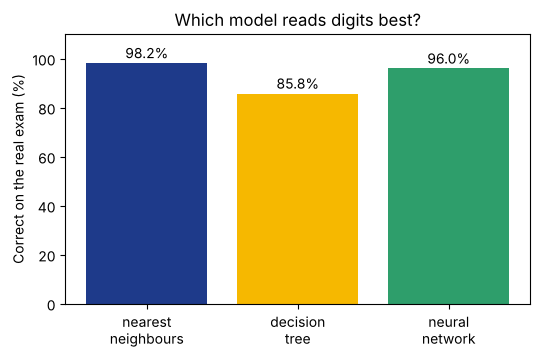

In [15]:
plt.figure(figsize=(6, 3.5))
short_names = ["nearest\nneighbours", "decision\ntree", "neural\nnetwork"]   # \n = new line
plt.bar(short_names, scores["accuracy (%)"], color=["#1E3A8A", "#F6B800", "#2E9E6B"])
for i in range(3):                                   # write the score on top of each bar
    value = scores["accuracy (%)"][i]
    plt.text(i, value + 2, f"{value:.1f}%", ha="center")
plt.ylim(0, 110)
plt.ylabel("Correct on the real exam (%)")
plt.title("Which model reads digits best?")
plt.show()

**Surprise?** On these tiny, tidy 8 x 8 pictures, the simple "nearest neighbours" method wins, and the neural network is a close second.
Neural networks shine when pictures are **big and messy** (real photos) and there are **lots** of examples.
Trying the simple tool first is a real data-science habit!

### The best model's mistakes
Which pictures did k-nearest neighbours get wrong? We collect them with a loop (L06):

Number of mistakes: 8


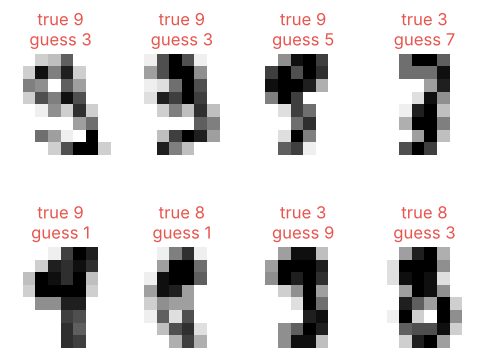

In [16]:
mistakes = []
for i in range(len(y_test)):
    if knn_predictions[i] != y_test[i]:
        mistakes.append(i)                 # remember where it went wrong
print("Number of mistakes:", len(mistakes))

plt.figure(figsize=(6, 4.6))
for spot in range(min(8, len(mistakes))):  # show at most 8
    i = mistakes[spot]
    plt.subplot(2, 4, spot + 1)                          # a 2 x 4 grid
    plt.imshow(X_test[i].reshape(8, 8), cmap="gray_r")   # reshape: 64 numbers back into 8 x 8
    plt.title(f"true {y_test[i]}\nguess {knn_predictions[i]}", color="#E8554E")
    plt.axis("off")
plt.show()

Be honest: would **you** have read all of these correctly? Some are really messy.

### Who gets confused with whom?
A **confusion matrix** is a table: each **row** is the true digit, each **column** is the model's guess.
The diagonal (top-left to bottom-right) counts the correct answers. Any number off the diagonal is a mistake.

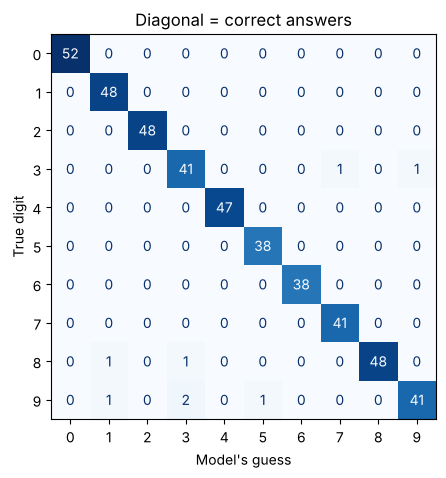

In [17]:
plt.figure(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, knn_predictions, colorbar=False,
                                        cmap="Blues", ax=plt.gca())   # gca = the current drawing area
plt.xlabel("Model's guess")
plt.ylabel("True digit")
plt.title("Diagonal = correct answers")
plt.show()

**Try this:** draw the confusion matrix for `network_predictions` and for `tree_predictions`. Which digits does the tree mix up?

## 5. More practice = a better student?
What if the models could study only a few pictures? `X_train[:size]` takes the first `size` pictures (slicing, L05).
`score` is a shortcut: predict + grade in one go (it gives a number from 0 to 1).

In [18]:
sizes = [20, 50, 100, 200, 500, 1347]
knn_scores = []
network_scores = []
for size in sizes:
    small_knn = KNeighborsClassifier(n_neighbors=3)
    small_knn.fit(X_train[:size], y_train[:size])             # study only the first `size` pictures
    knn_scores.append(100 * small_knn.score(X_test, y_test))  # same real exam every time
    small_network = MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=7)
    small_network.fit(X_train[:size], y_train[:size])
    network_scores.append(100 * small_network.score(X_test, y_test))
print(pd.DataFrame({"pictures studied": sizes, "kNN (%)": knn_scores,
                    "network (%)": network_scores}).round(1))

   pictures studied  kNN (%)  network (%)
0                20     48.0         60.2
1                50     76.2         80.9
2               100     90.0         90.7
3               200     93.3         90.9
4               500     95.1         94.4
5              1347     98.2         96.0


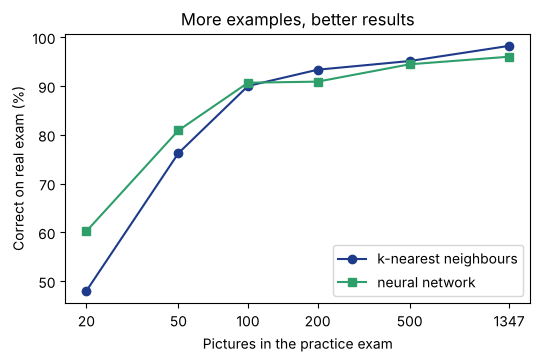

In [19]:
plt.figure(figsize=(6, 3.5))
plt.plot(sizes, knn_scores, marker="o", color="#1E3A8A", label="k-nearest neighbours")
plt.plot(sizes, network_scores, marker="s", color="#2E9E6B", label="neural network")
plt.xscale("log")              # log scale: 10, 100, 1000 get equal space
plt.xticks(sizes, sizes)       # put a tick at each size we tried
plt.minorticks_off()
plt.xlabel("Pictures in the practice exam")
plt.ylabel("Correct on real exam (%)")
plt.title("More examples, better results")
plt.legend()
plt.show()

Both models get much better with more examples. With very few examples, both are poor.
**Big AI systems learn from huge numbers of examples** for exactly this reason.

## 6. From ML to neural networks: what is inside?
Here is our network as a diagram:

```
 [ 64 inputs ]  ---->  [ 50 hidden neurons ]  ---->  [ 10 outputs ]
  one per pixel          each one looks for a         one per digit:
  (0 = paper,            pattern in the pixels        "how much does this
   1 = ink)                                            look like a 0? a 1? ..."

 Every input is connected to every hidden neuron, and every hidden neuron
 to every output. Each connection has its own KNOB (a number called a "weight").
```

- Each hidden neuron takes **all 64 pixels**, multiplies each one by its own **knob**, and adds them up.
  The result says "how strongly do I see my pattern?" (maybe a curve at the top, or a line in the middle).
- Each output neuron does the same with the 50 hidden neurons. **The output with the biggest number wins.**
- **Learning = adjusting the knobs.** At the start the knobs are random and the answers are nonsense.
  After each round of practice, every knob is turned **a tiny bit** in the direction that makes **fewer mistakes**.
  After a few hundred rounds, the answers are good.

How many knobs does our small network have? Let's count (`coefs_` = the weights, `intercepts_` = one extra knob per neuron):

In [20]:
total_knobs = 0
for layer_knobs in network.coefs_:        # weights between two layers
    print("knobs between layers:", layer_knobs.shape)
    total_knobs = total_knobs + layer_knobs.size
for extra_knobs in network.intercepts_:   # one extra knob per neuron
    total_knobs = total_knobs + extra_knobs.size
print("Total knobs in our network:", total_knobs)

knobs between layers: (64, 50)
knobs between layers: (50, 10)
Total knobs in our network: 3760


`(64, 50)`: every one of the 64 pixels is connected to every one of the 50 hidden neurons: 64 x 50 = 3,200 knobs.

### Watch it learn
While it studied, the network kept a **mistake score** (called the *loss*) after every round. Lower = fewer mistakes.

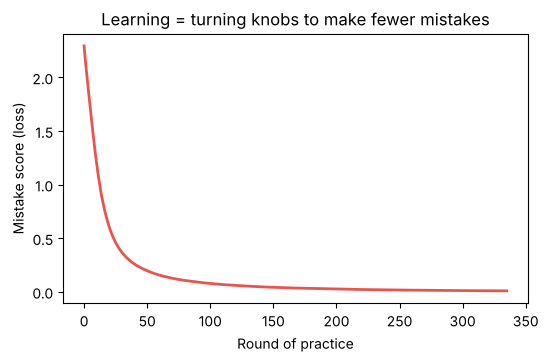

Rounds of practice: 336


In [21]:
plt.figure(figsize=(6, 3.5))
plt.plot(network.loss_curve_, color="#E8554E", linewidth=2)
plt.xlabel("Round of practice")
plt.ylabel("Mistake score (loss)")
plt.title("Learning = turning knobs to make fewer mistakes")
plt.show()
print("Rounds of practice:", network.n_iter_)

### The 10 outputs, for one picture
`predict_proba` shows the 10 outputs as chances (they add up to 1). The biggest one becomes the answer.
Picture number 125 of the real exam is a tricky one:

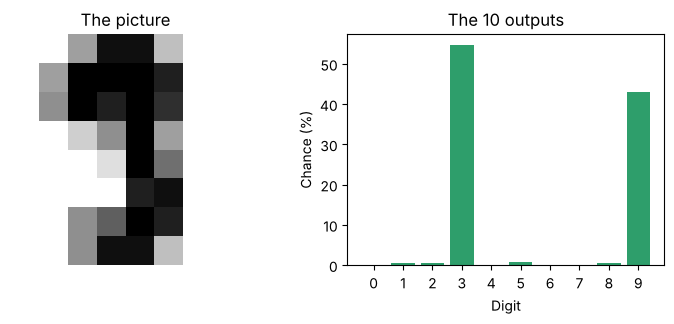

In [22]:
picture = X_test[125:126]                           # picture number 125 (a table with 1 row)
chances = network.predict_proba(picture)[0]         # 10 numbers, one per digit
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1)
plt.imshow(picture.reshape(8, 8), cmap="gray_r")
plt.title("The picture")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.bar(range(10), chances * 100, color="#2E9E6B")
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Chance (%)")
plt.title("The 10 outputs")
plt.show()

A close call between a 3 and a 9! The biggest output wins (3), and this time the network is right.
A picture with one tall bar is an easy one: the network is sure.

### The same idea, scaled up
| Our network | Big AI systems |
|---|---|
| 8 x 8 gray pictures | photos with millions of colored pixels |
| 1 hidden layer | many layers stacked on top of each other ("deep learning") |
| a few thousand knobs | millions, and for big language models, billions of knobs |
| about 1,350 practice pictures | huge collections of examples |
| seconds on a laptop | weeks on many special computers |

- **Photo apps** that find "cat" or "beach" in your gallery: pixels in, labels out.
- **Self-driving cars**: camera pixels in, "pedestrian / lane / stop sign" out.
- **Chatbots (LLMs)**: words in (as numbers, L01 "tokens"), **the next word** out.

Same recipe every time: **inputs -> layers of neurons -> outputs**, and learning = turning the knobs to make fewer mistakes.

## 7. Limits: it only knows what it saw
Our network has only ever seen **centered, dark-ink-on-white** digits. What happens with something unusual?
We change a picture of a 5 with NumPy (L09). `np.roll` slides the pixels (what falls off one side comes back on the other),
`1 - original` swaps ink and paper (like `255 - cat` in L09), and the noise is random dots, not a digit at all.

In [23]:
original = X_test[2].reshape(8, 8)               # a 5 from the real exam
shifted = np.roll(original, 2, axis=1)           # slide 2 pixels right
inverted = 1 - original                          # swap ink and paper
noise = np.random.default_rng(7).random((8, 8))  # random dots
tests = [original, shifted, inverted, noise]
test_names = ["original", "shifted right", "inverted", "random noise"]
print("True label of the original:", y_test[2])

True label of the original: 5


original       -> network says 5 (100% sure), kNN says 5


shifted right  -> network says 3 (100% sure), kNN says 1
inverted       -> network says 4 (99% sure), kNN says 1


random noise   -> network says 4 (88% sure), kNN says 5


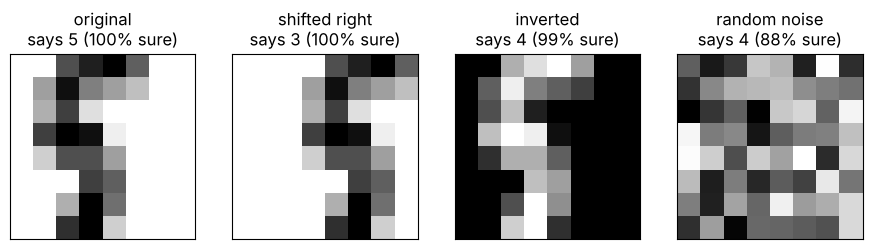

In [24]:
plt.figure(figsize=(11, 3))
for k in range(4):
    as_row = tests[k].reshape(1, 64)                       # back to one row of 64 numbers
    guess = network.predict(as_row)[0]
    sure = 100 * network.predict_proba(as_row).max()      # how "sure" the network is
    print(f"{test_names[k]:14} -> network says {guess} ({sure:.0f}% sure), kNN says {knn.predict(as_row)[0]}")
    plt.subplot(1, 4, k + 1)
    plt.imshow(tests[k], cmap="gray_r", vmin=0, vmax=1)
    plt.title(f"{test_names[k]}\nsays {guess} ({sure:.0f}% sure)")
    plt.xticks([])                                          # keep the frame, hide tick numbers
    plt.yticks([])
plt.show()

The network is **very sure** about answers that are **wrong**, and it gives a confident answer even for random noise.
It never says "I don't know". (Sounds familiar? Chatbots can also be confidently wrong, L01.)

**Lesson:** a model only knows the kind of examples it practiced on. Real systems are trained with many more varied
examples (shifted, rotated, different pens, different light), and people still have to test them carefully.

## 8. Draw your own digit
Each number is a pixel from 0 (paper) to 16 (ink). Here is a hand-made **7**. Change the numbers to draw your own digit!

In [25]:
my_digit = np.array([
    [0, 0,  0,  0,  0,  0, 0, 0],
    [0, 4, 16, 16, 16, 16, 8, 0],
    [0, 0,  0,  0,  0, 12, 8, 0],
    [0, 0,  0,  0,  4, 16, 0, 0],
    [0, 0,  0,  0, 12,  8, 0, 0],
    [0, 0,  0,  4, 16,  0, 0, 0],
    [0, 0,  0, 12,  8,  0, 0, 0],
    [0, 0,  0, 16,  4,  0, 0, 0],
]) / 16                                          # same 0-to-1 scale as the practice pictures

kNN says: 7
Network says: 7


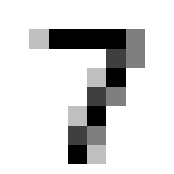

In [26]:
as_row = my_digit.reshape(1, 64)
print("kNN says:", knn.predict(as_row)[0])
print("Network says:", network.predict(as_row)[0])
plt.figure(figsize=(2, 2))
plt.imshow(my_digit, cmap="gray_r")
plt.axis("off")
plt.show()

## Challenges
**Easy**
- Use `n_neighbors=1`, `5` and `15` for kNN. Make a small table of the results.
- Draw a **1** and a **0** in the "draw your own digit" cell. Does the network read them?

**Medium**
- Write a loop over `max_depth` from 1 to 15 for the decision tree, save each accuracy in a list, and plot accuracy vs depth.
- Try networks with `(10,)`, `(50,)` and `(200,)` hidden neurons. Count the knobs of each. Is bigger always better here?

**Spicy**
- Make the network survive the inverted test! Add inverted copies of the practice pictures to the practice exam:
  `X_bigger = np.vstack([X_train, 1 - X_train])` and `y_bigger = np.concatenate([y_train, y_train])`.
  Train a new network on them and test it on `1 - X_test`. What changed, and what does that teach you about training data?

> **Pip says:** "You just trained three AI models and caught one lying with confidence. Not bad for a snake's student!"